# E5. Kết hợp model

Đây là bước Ensemble của ML pipeline (Bài 10): kết hợp dự đoán của nhiều model bằng trung bình (averaging), trung
bình có trọng số (weighted), trung bình thứ hạng (rank averaging), blending và stacking. Mọi phương pháp chạy trên OOF
của cùng `data/folds.csv`. Phương pháp nào học trọng số từ OOF thì được chấm bằng nested CV (meta model fit trên 4
fold OOF, chấm trên fold còn lại), với 2 cách chia meta fold.

> **Trong cuộc thi.** Stacking là bước mang lại nhiều điểm nhất:
>
> | Ngày | Stack | CV | Ghi chú |
> | --- | --- | --- | --- |
> | 15/10 | `A_lgb` + `A_lr` (stack LR 2 member) | 0,96103 | +8×10⁻⁵ so với LightGBM đơn |
> | 15/10 | 251 OOF công khai, LR theo họ + LightGBM (`stack_fw_p247`) | 0,962218 | bài nộp slot 1, **private 0,96239** |
> | 19/10 | chỉ model nhóm tự train (10 model) | 0,96121 | |
> | 19/10 | 10 model nhóm + 15 foundation model công khai | 0,96180 | nhóm thêm +1,6×10⁻⁴ so với 15 foundation model |
> | 19/10 | thêm model nhóm vào pool công khai đầy đủ | ±0 | pool công khai đã chứa thông tin đó |
> | 25/10 | stack công khai + Q-FT ×1,5 (`stack_v17_qft15`) | 0,962224 | qua cổng, 14/15 fold; bài nộp dùng bản Q-FT trung bình 2 seed (`stack_v17b_qft15`) |
>
> Ở E3, stacking 25 OOF sạch của nhóm đạt 0,961619. Phần dưới so sánh các cách kết hợp trên chính bộ OOF đó và trên
> 12 model của E3, để kiểm tra lựa chọn stacking bằng LR trên logit của nhóm.

Nội dung:
1. Hai bộ member
2. Trung bình: xác suất, logit, thứ hạng
3. Chọn member tham lam (Caruana) và trung bình có trọng số
4. Blending và stacking (LR với nhiều mức regularization, LightGBM); ghép LightGBM với từng model
5. Cần bao nhiêu member
6. Tóm tắt và quyết định

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import os
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from blend import meta_folds, to_logit
from config import N_FOLDS, OOF_DIR, RESULTS_DIR, ROOT, TARGET
from data import load_data
import plot as P

pd.set_option("display.width", 200)
train, _ = load_data()
y, fold = train[TARGET].values, train["fold"].values
del train
COMP_OOF = Path(os.environ.get("COMP_OOF_DIR", ROOT.parent / "DoAn" / "oof"))
KAGGLE_E3 = RESULTS_DIR / "E3_models"
RES = RESULTS_DIR / "E5_ensemble.csv"
SEEDS = {"folds.csv": fold, "seed 7": meta_folds(y, 7)}

## 1. Hai bộ member
- Bộ E3: 12 model của E3 (bỏ cây không giới hạn độ sâu và Naive Bayes Gaussian), cùng 21 cột gốc, chỉ khác nhau ở
  thuật toán.
- Bộ nhóm: 25 OOF sạch của nhóm khi thi (E3 mục 1), khác nhau ở cả thuật toán, feature và cách dùng dữ liệu gốc.

Mọi member được đưa về thang logit trước khi kết hợp (`src/blend.py`).

In [2]:
E3_NAMES = ["lightgbm", "xgboost", "catboost", "hist_gb", "random_forest", "extra_trees", "mlp", "rbf_svm",
            "decision_tree", "logistic_regression", "linear_svm", "naive_bayes_cat"]
TEAM = ["A_lgb_v1", "A_lgb_v2", "A_lgb_origrow_v1", "A_lgb_noorig_v1", "A_lgb_wper3_v1",
        "quan_cat_dual_teacher_v4", "quan_xgb_dual_teacher_v4", "quan_xgb_safe_teacher_v4", "quan_xgb_original_aug_v4",
        "A_kozy_v1", "A_kozy_raw_v1", "A_kozy_prior_v1", "A_lr_v1", "A_lr_v2", "A_glr_v1", "A_knn_v1", "A_knn_v2",
        "A_fm_v1", "A_tabm_v1", "A_ftt_v1", "B_realmlp_v1", "A_gptc_v1", "A_qft2_v2", "A_qft2_v2s7", "A_qft2_v2avg"]


def load_pool(names, path_of):
    Z = np.column_stack([to_logit(*(2 * [np.load(path_of(n))]))[0] for n in names]).astype(np.float64)
    return pd.DataFrame(Z, columns=names)


POOLS = {
    "E3": load_pool(E3_NAMES, lambda n: KAGGLE_E3 / f"oof_E3_{n}.npy" if (KAGGLE_E3 / f"oof_E3_{n}.npy").exists()
                    else OOF_DIR / f"oof_E3_{n}.npy"),
    "nhóm": load_pool(TEAM, lambda n: COMP_OOF / f"oof_{n}.npy"),
}
for name, Z in POOLS.items():
    aucs = Z.apply(lambda c: roc_auc_score(y, c))
    print(f"bộ {name}: {Z.shape[1]} member, AUC đơn tốt nhất {aucs.max():.6f} ({aucs.idxmax()})")

bộ E3: 12 member, AUC đơn tốt nhất 0.958595 (lightgbm)


bộ nhóm: 25 member, AUC đơn tốt nhất 0.961304 (A_qft2_v2avg)


Các hàm kết hợp. Trong `nested(fit_predict)`, với mỗi meta fold k, `fit_predict(Z_train, y_train, Z_val)` chỉ thấy 4
fold còn lại; điểm là AUC trên toàn bộ OOF meta. Kết quả được cache vào `results/E5_ensemble.csv`.

In [3]:
def auc(p):
    return roc_auc_score(y, p)


def nested(fit_predict, Z, folds):
    out = np.zeros(len(y))
    for k in range(N_FOLDS):
        tr, va = folds != k, folds == k
        out[va] = fit_predict(Z[tr], y[tr], Z[va])
    return out


def fp_lr(C, scale=False):
    def f(Ztr, ytr, Zva):
        if scale:
            mu, sd = Ztr.mean(0), Ztr.std(0)
            Ztr, Zva = (Ztr - mu) / sd, (Zva - mu) / sd
        m = LogisticRegression(C=C, tol=1e-6, max_iter=20000).fit(Ztr, ytr)
        return m.decision_function(Zva)
    return f


def fp_lgb(Ztr, ytr, Zva):
    rng = np.random.default_rng(0)
    es = rng.random(len(ytr)) < 0.1
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=15, min_child_samples=200,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, n_jobs=4, verbose=-1,
                           random_state=0)
    m.fit(Ztr[~es], ytr[~es], eval_set=[(Ztr[es], ytr[es])], eval_metric="auc",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.predict_proba(Zva, raw_score=True)


def caruana(Ztr, ytr, n_steps=40):
    """Chọn member tham lam có hoàn lại (Caruana 2004): mỗi bước thêm member làm AUC trung bình logit tăng nhiều nhất."""
    counts, cur = np.zeros(Ztr.shape[1]), np.zeros(len(ytr))
    for step in range(n_steps):
        scores = [roc_auc_score(ytr, (cur * step + Ztr[:, j]) / (step + 1)) for j in range(Ztr.shape[1])]
        j = int(np.argmax(scores))
        counts[j] += 1
        cur = (cur * step + Ztr[:, j]) / (step + 1)
    return counts / counts.sum()


def fp_caruana(Ztr, ytr, Zva):
    sub = np.random.default_rng(0).random(len(ytr)) < 0.3  # 30% dòng để chọn nhanh hơn
    return Zva @ caruana(Ztr[sub], ytr[sub])


cache = pd.read_csv(RES) if RES.exists() else pd.DataFrame(columns=["pool", "method", "seed"])


def record(pool, method, fn, nested_fp=None, notes=""):
    """fn: () -> dự đoán (không học trọng số); nested_fp: fit_predict cho nested CV trên từng cách chia meta fold."""
    global cache
    Z = POOLS[pool].values
    for seed, folds in (SEEDS.items() if nested_fp else [("–", None)]):
        hit = cache[(cache["pool"] == pool) & (cache["method"] == method) & (cache["seed"] == seed)]
        if len(hit):
            continue
        t0 = time.time()
        p = nested(nested_fp, Z, folds) if nested_fp else fn()
        fa = [roc_auc_score(y[fold == k], p[fold == k]) for k in range(N_FOLDS)]
        row = {"pool": pool, "method": method, "seed": seed, "cv_auc": round(auc(p), 6),
               **{f"fold_{k}": round(a, 6) for k, a in enumerate(fa)},
               "seconds": round(time.time() - t0, 1), "notes": notes}
        cache = pd.concat([cache, pd.DataFrame([row])], ignore_index=True)
        cache.to_csv(RES, index=False)
        print(f"[{pool}] {method:38s} {seed:9s} {row['cv_auc']:.6f} ({row['seconds']}s)")

## 2. Trung bình: xác suất, logit, hạng
Các cách này không học từ nhãn nên không cần nested CV. "Member tốt nhất" là member có AUC cao nhất; vì được chọn
bằng nhãn nên con số này hơi lạc quan. "5 member AUC cao nhất" cũng chọn bằng nhãn.

In [4]:
for pool, Z in POOLS.items():
    record(pool, "member tốt nhất", lambda Z=Z: Z.values[:, Z.apply(auc).values.argmax()])
    record(pool, "TB xác suất", lambda Z=Z: (1 / (1 + np.exp(-Z.values))).mean(1))
    record(pool, "TB logit", lambda Z=Z: Z.values.mean(1))
    record(pool, "TB hạng", lambda Z=Z: np.column_stack([rankdata(Z[c]) for c in Z]).mean(1))
    top = Z.apply(auc).sort_values(ascending=False).index[:5]
    record(pool, "TB logit 5 member AUC cao nhất", lambda Z=Z, top=top: Z[top].values.mean(1))

## 3. Chọn member tham lam và trung bình có trọng số
Theo Caruana và cộng sự (2004): bắt đầu từ tập rỗng, mỗi bước thêm (có hoàn lại) member làm AUC của trung bình logit
tăng nhiều nhất; số lần một member được chọn là trọng số của nó. Trọng số học trên 4 fold và chấm trên fold còn lại.

In [5]:
for pool in POOLS:
    record(pool, "Caruana (40 bước, trọng số ≥ 0)", None, fp_caruana)

## 4. Blending và stacking
- Blending: meta model (LR) chỉ fit trên một fold OOF (fold 0, 20% dữ liệu) rồi chấm trên 4 fold còn lại, tức là
  dùng một tập holdout cố định như trong Bài 10. Để so sánh công bằng, phần này chấm mọi phương pháp chỉ trên fold 1–4.
- Stacking LR trên logit với nhiều mức C (C nhỏ là regularization mạnh), có và không chuẩn hoá cột.
- Stacking LightGBM: meta model phi tuyến, cây nông, early stopping trên 10% phần train của meta fold.

In [6]:
for pool in POOLS:
    for C in [0.0003, 0.003, 0.03, 1.0]:
        record(pool, f"stack LR C={C}", None, fp_lr(C))
    record(pool, "stack LR C=1, chuẩn hoá cột", None, fp_lr(1.0, scale=True))
    record(pool, "stack LightGBM", None, fp_lgb)

In [7]:
BLEND = RESULTS_DIR / "E5_blending.csv"
if not BLEND.exists():
    rows = []
    rest = fold != 0
    for pool, Z in POOLS.items():
        Zv = Z.values
        m = LogisticRegression(C=0.003, tol=1e-6, max_iter=20000).fit(Zv[fold == 0], y[fold == 0])
        rows.append({"pool": pool, "method": "blending (LR fit trên fold 0)",
                     "auc_fold1_4": roc_auc_score(y[rest], m.decision_function(Zv[rest]))})
        st = nested(fp_lr(0.003), Zv, fold)
        rows.append({"pool": pool, "method": "stacking LR C=0.003 (nested)", "auc_fold1_4": roc_auc_score(y[rest], st[rest])})
        rows.append({"pool": pool, "method": "TB logit", "auc_fold1_4": roc_auc_score(y[rest], Zv[rest].mean(1))})
    pd.DataFrame(rows).to_csv(BLEND, index=False)
blend = pd.read_csv(BLEND)
blend.pivot(index="method", columns="pool", values="auc_fold1_4").round(6)

pool,E3,nhóm
method,,
TB logit,0.956007,0.960442
blending (LR fit trên fold 0),0.958891,0.961567
stacking LR C=0.003 (nested),0.958896,0.961568


In [8]:
res = pd.read_csv(RES)
best = res[res["method"] == "member tốt nhất"].set_index("pool")["cv_auc"]
res["Δ so với member tốt nhất"] = res["cv_auc"] - res["pool"].map(best)
tab = res.pivot_table(index="method", columns=["pool", "seed"], values="cv_auc", sort=False)
tab.round(6)

pool                                   E3      nhóm        E3                nhóm          
seed                                    –         – folds.csv    seed 7 folds.csv    seed 7
method                                                                                     
member tốt nhất                  0.958595  0.961304       NaN       NaN       NaN       NaN
TB xác suất                      0.956796  0.960669       NaN       NaN       NaN       NaN
TB logit                         0.956094  0.960485       NaN       NaN       NaN       NaN
TB hạng                          0.957349  0.961063       NaN       NaN       NaN       NaN
TB logit 5 member AUC cao nhất   0.958854  0.961589       NaN       NaN       NaN       NaN
Caruana (40 bước, trọng số ≥ 0)       NaN       NaN  0.958871  0.958800  0.961571  0.961582
stack LR C=0.0003                     NaN       NaN  0.958889  0.958902  0.961605  0.961609
stack LR C=0.003                      NaN       NaN  0.958906  0.958923  0.961619  0.961628
stack LR C=0.03                       NaN       NaN  0.958897  0.958914  0.961616  0.961626
stack LR C=1.0                        NaN       NaN  0.958892  0.958910  0.961613  0.961624
stack LR C=1, chuẩn hoá cột           NaN       NaN  0.958892  0.958910  0.961614  0.961625
stack LightGBM                        NaN       NaN  0.958832  0.959028  0.961486  0.960875

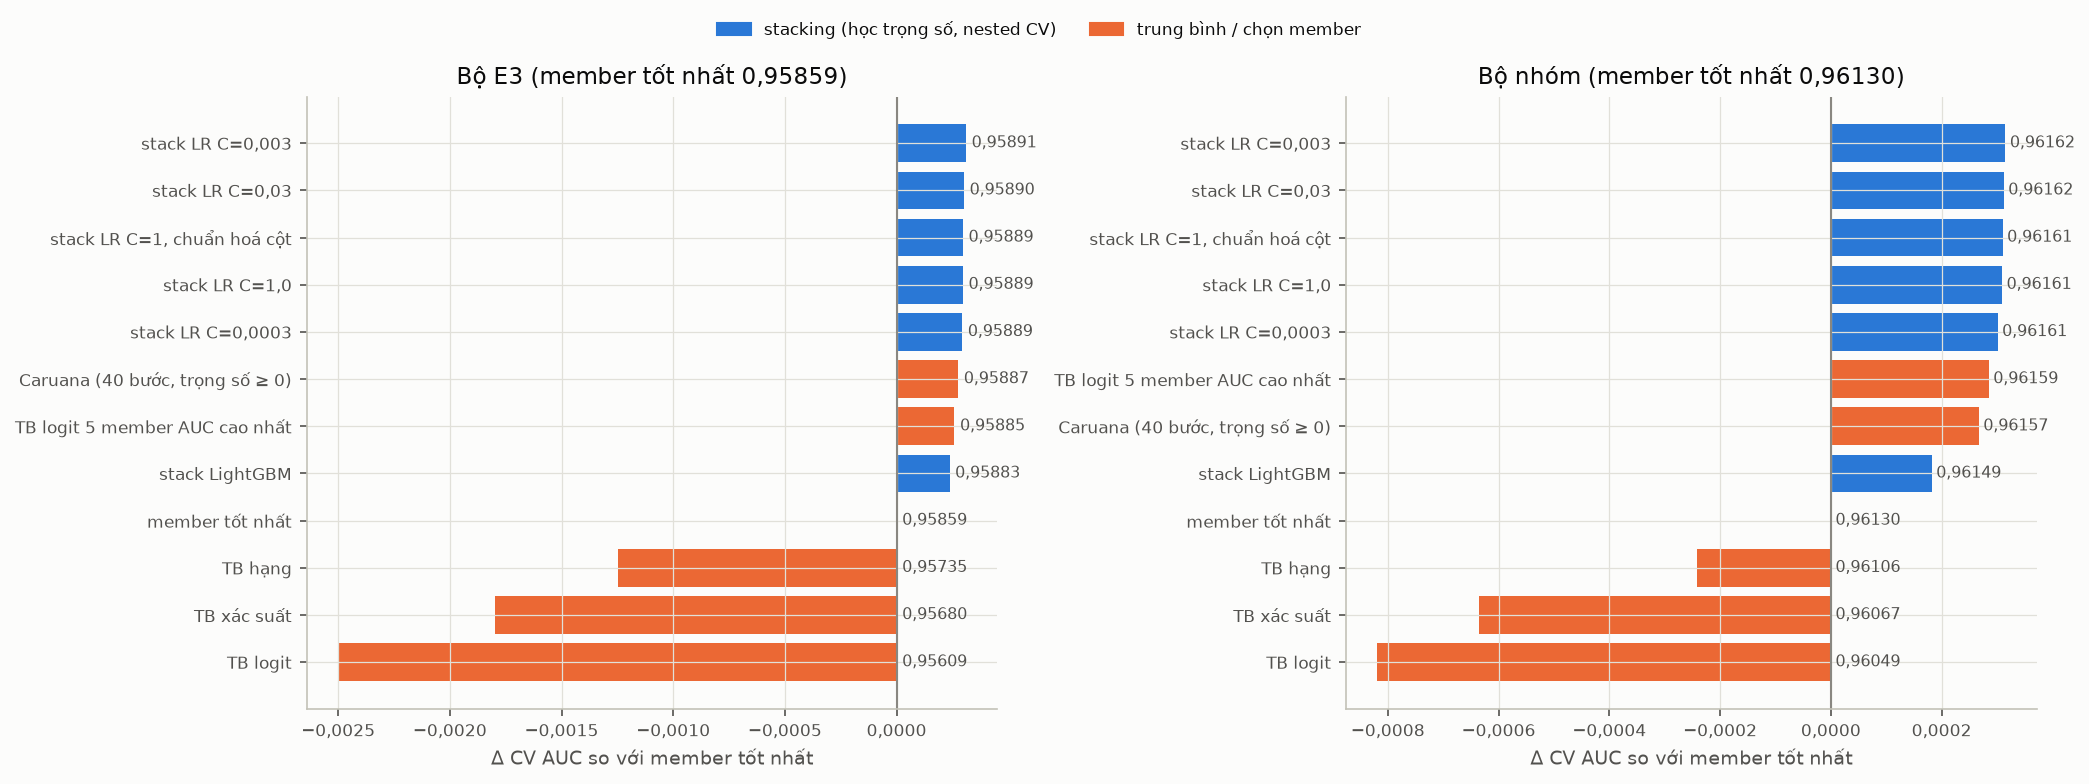

In [9]:
order = res[res["seed"].isin(["–", "folds.csv"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, pool in zip(axes, POOLS):
    d = order[order["pool"] == pool].sort_values("cv_auc")
    colors = [P.INK_3 if m == "member tốt nhất" else (P.BLUE if m.startswith("stack") else P.ORANGE) for m in d["method"]]
    ax.barh(d["method"], d["cv_auc"] - best[pool], color=colors)
    span = (d["cv_auc"] - best[pool]).abs().max()
    for i, (v, a) in enumerate(zip(d["cv_auc"] - best[pool], d["cv_auc"])):
        ax.text(max(v, 0) + span * 0.01, i, f"{a:.5f}", va="center", ha="left", fontsize=7.5, color=P.INK_2)
    ax.axvline(0, color=P.REF, lw=1)
    ax.set_xlabel("Δ CV AUC so với member tốt nhất")
    ax.set_title(f"Bộ {pool} (member tốt nhất {best[pool]:.5f})")
from matplotlib.patches import Patch  # noqa: E402
fig.legend(handles=[Patch(color=P.BLUE, label="stacking (học trọng số, nested CV)"),
                    Patch(color=P.ORANGE, label="trung bình / chọn member")],
           loc="upper center", bbox_to_anchor=(0.5, 1.05), ncol=2)
fig.tight_layout()
P.save(fig, "E5_01_methods")

**Nhận xét mục 2–4**
- Trung bình đều mọi member đều thấp hơn member tốt nhất: trên bộ E3 giảm 1,2×10⁻³ (thứ hạng) đến 2,5×10⁻³ (logit),
  trên bộ nhóm giảm 2,4×10⁻⁴ đến 8,2×10⁻⁴. Với trọng số bằng nhau, các member yếu (Naive Bayes, kNN) kéo kết quả
  xuống. Trung bình thứ hạng ít bị ảnh hưởng hơn trung bình logit, vì member có logit lớn bất thường không áp đảo được.
- Chỉ lấy trung bình 5 member AUC cao nhất đã vượt member tốt nhất (+2,6×10⁻⁴ trên bộ E3, +2,9×10⁻⁴ trên bộ nhóm).
  Caruana tự chọn trọng số và cho kết quả tương tự (0,95887 và 0,96157), nhưng vẫn thấp hơn stacking LR khoảng
  4×10⁻⁵.
- Stacking LR đạt 0,958906 trên bộ E3 (+3,1×10⁻⁴ so với LightGBM) và 0,961619 trên bộ nhóm (+3,2×10⁻⁴ so với Q-FT),
  chênh không quá 2×10⁻⁵ giữa hai cách chia meta fold. Đổi C từ 0,0003 đến 1 làm AUC thay đổi không quá 1,7×10⁻⁵
  (bộ E3) và 1,4×10⁻⁵ (bộ nhóm); chuẩn hoá cột không ảnh hưởng.
- Blending (fit chỉ trên fold 0) gần như bằng stacking khi chấm trên cùng fold 1–4 (chênh 5×10⁻⁶ và 1×10⁻⁶). Stacker
  LR chỉ có 12–25 tham số nên 140 nghìn dòng của một fold đã đủ để ước lượng; lợi thế của stacking là dùng được toàn
  bộ dữ liệu để chấm và có thể chạy nhiều meta seed.
- Stacking bằng LightGBM dao động mạnh giữa hai meta seed. Trên bộ E3, với meta fold seed 7 nó đạt 0,95903, cao hơn
  LR 1,1×10⁻⁴, nhưng với `folds.csv` lại thấp hơn LR 7×10⁻⁵. Trên bộ nhóm nó thấp hơn LR ở cả hai seed (0,96149 và
  0,96088). Có thể do meta model phi tuyến dễ học theo nhiễu của OOF hơn là học được tương tác có ích.

### 4.1 Ghép LightGBM với từng model của E3
Stacking LR (C = 0,003) trên hai cột [LightGBM, model X], chấm bằng nested CV trên `folds.csv`. Phép đo này kiểm tra
nhận định ở E3 rằng model khác loại, tương quan thấp, mới thêm được thông tin.

In [10]:
PAIR = RESULTS_DIR / "E5_pairs_lgb.csv"
if not PAIR.exists():
    Z = POOLS["E3"]
    base = auc(Z["lightgbm"])
    rows = []
    for c in Z.columns:
        if c == "lightgbm":
            continue
        p = nested(fp_lr(0.003), Z[["lightgbm", c]].values, fold)
        rows.append({"model": c, "auc_rieng": auc(Z[c]),
                     "rank_corr_lgb": np.corrcoef(rankdata(Z["lightgbm"]), rankdata(Z[c]))[0, 1],
                     "auc_lgb_cong_x": auc(p), "delta_vs_lgb": auc(p) - base,
                     "fold_tang": int(sum(roc_auc_score(y[fold == k], p[fold == k]) >
                                          roc_auc_score(y[fold == k], Z["lightgbm"].values[fold == k]) for k in range(N_FOLDS)))})
    pd.DataFrame(rows).sort_values("delta_vs_lgb", ascending=False).to_csv(PAIR, index=False)
pairs = pd.read_csv(PAIR)
pairs.round(6)

,model,auc_rieng,rank_corr_lgb,auc_lgb_cong_x,delta_vs_lgb,fold_tang
0,catboost,0.958555,0.971190,0.958859,0.000264,5
1,xgboost,0.958585,0.977062,0.958811,0.000216,5
2,hist_gb,0.958241,0.971215,0.958708,0.000112,4
3,mlp,0.956163,0.916719,0.958647,0.000051,4
4,random_forest,0.956545,0.928865,0.958615,0.000020,3
5,extra_trees,0.956089,0.928812,0.958600,0.000005,2
6,decision_tree,0.951289,0.909515,0.958587,-0.000009,2
7,rbf_svm,0.951787,0.901447,0.958581,-0.000014,2
8,linear_svm,0.947626,0.887874,0.958573,-0.000023,2
9,naive_bayes_cat,0.930901,0.815701,0.958572,-0.000023,3


**Nhận xét 4.1**
- Kết quả ngược với dự đoán ở E3. Hai model boosting khác thư viện thêm được nhiều nhất: CatBoost +2,6×10⁻⁴ và XGBoost
  +2,2×10⁻⁴ (5/5 fold), dù tương quan rank với LightGBM tới 0,97–0,98. MLP, tương quan thấp hơn hẳn (0,917), chỉ thêm
  5×10⁻⁵. Random Forest và Extra Trees thêm khoảng 2×10⁻⁵ trở xuống; các model yếu hơn (cây đơn, SVM, LR, Naive Bayes) làm giảm.
- Như vậy tương quan thấp chưa đủ để một member có ích; member còn phải đủ mạnh. CatBoost và XGBoost có AUC ngang
  LightGBM nhưng dựng cây và xử lý category theo cách khác; có thể vì vậy chúng sai ở những dòng khác nhau dù tương quan
  tổng thể cao.
- Riêng LightGBM + CatBoost (0,958859) đã đạt khoảng 85% mức tăng của stacking cả 12 model (0,958906).

## 5. Cần bao nhiêu member
Thêm dần member theo hai thứ tự: (a) AUC riêng giảm dần; (b) tham lam theo stacking, mỗi bước thêm member làm AUC
của stacking LR tăng nhiều nhất (chọn trên 20% số dòng, nên thứ tự này hơi lạc quan). Mỗi bước được chấm bằng nested
CV đầy đủ, stacking LR với C = 0,003.

In [11]:
CURVE = RESULTS_DIR / "E5_members_curve.csv"
if not CURVE.exists():
    rows = []
    Z = POOLS["nhóm"]
    by_auc = list(Z.apply(auc).sort_values(ascending=False).index)
    for k in range(1, len(by_auc) + 1):
        p = nested(fp_lr(0.003), Z[by_auc[:k]].values, fold)
        rows.append({"order": "AUC riêng", "k": k, "added": by_auc[k - 1], "cv_auc": auc(p)})
        print("auc", k, round(rows[-1]["cv_auc"], 6))
    chosen, left = [], list(Z.columns)
    sub = np.random.default_rng(0).random(len(y)) < 0.2  # chọn trên 20% dòng (≤ 10 cột nên gần như không overfit)
    for k in range(1, 11):
        cand = {}
        for c in left:
            Zs = Z[chosen + [c]].values[sub]
            m = LogisticRegression(C=0.003, tol=1e-6, max_iter=20000).fit(Zs, y[sub])
            cand[c] = roc_auc_score(y[sub], m.decision_function(Zs))
        c = max(cand, key=cand.get)
        chosen.append(c)
        left.remove(c)
        p = nested(fp_lr(0.003), Z[chosen].values, fold)
        rows.append({"order": "tham lam theo stack", "k": k, "added": c, "cv_auc": auc(p)})
        print("greedy", k, c, round(rows[-1]["cv_auc"], 6))
    pd.DataFrame(rows).to_csv(CURVE, index=False)
curve = pd.read_csv(CURVE)
curve[curve["order"] == "tham lam theo stack"]

,order,k,added,cv_auc
25,tham lam theo stack,1,A_qft2_v2avg,0.961298
26,tham lam theo stack,2,A_lgb_v1,0.961560
27,tham lam theo stack,3,A_kozy_prior_v1,0.961560
28,tham lam theo stack,4,A_glr_v1,0.961580
29,tham lam theo stack,5,quan_xgb_original_aug_v4,0.961581
30,tham lam theo stack,6,A_lr_v1,0.961591
31,tham lam theo stack,7,A_lgb_noorig_v1,0.961595
32,tham lam theo stack,8,quan_cat_dual_teacher_v4,0.961617
33,tham lam theo stack,9,A_kozy_raw_v1,0.961618
34,tham lam theo stack,10,A_ftt_v1,0.961613


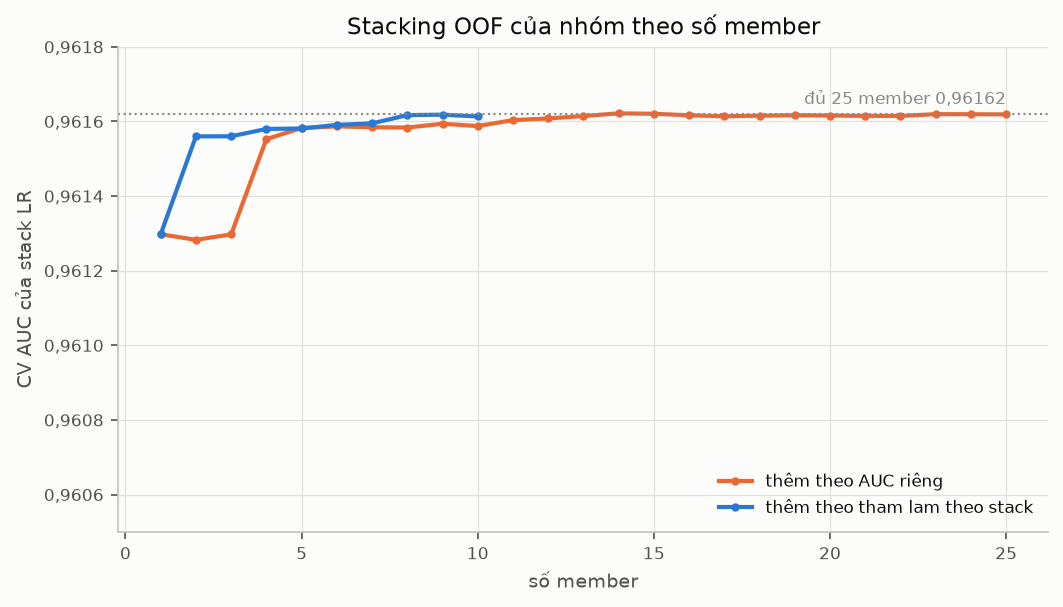

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for o, c in [("AUC riêng", P.ORANGE), ("tham lam theo stack", P.BLUE)]:
    d = curve[curve["order"] == o]
    ax.plot(d["k"], d["cv_auc"], color=c, marker="o", markersize=3, label=f"thêm theo {o}")
full25 = res[(res["pool"] == "nhóm") & (res["method"] == "stack LR C=0.003") & (res["seed"] == "folds.csv")]["cv_auc"].item()
ax.axhline(full25, color=P.REF, lw=1, ls=":")
ax.annotate(f"đủ 25 member {full25:.5f}", (25, full25), textcoords="offset points", xytext=(0, 5), ha="right",
            fontsize=8, color=P.INK_3)
ax.set_xlabel("số member")
ax.set_ylabel("CV AUC của stack LR")
ax.set_ylim(0.9605, 0.9618)
ax.set_title("Stacking OOF của nhóm theo số member")
ax.legend(loc="lower right")
P.save(fig, "E5_02_members")

**Nhận xét mục 5**
- Thêm theo thứ tự tham lam, 2 member (Q-FT trung bình 2 seed và `A_lgb_v1`) đã đạt 0,961560, tức khoảng 80% mức tăng
  của cả 25 member so với member tốt nhất. Tám member đạt 0,961617, ngang bộ đầy đủ (0,961619).
- Thêm theo AUC riêng thì 3 member đầu đều là các bản Q-FT, gần như trùng nhau, nên stacking không tăng (0,96128–
  0,96130). Chỉ khi thêm `A_lgb_v1` ở bước 4 thì AUC mới nhảy lên 0,961553.
- Từ khoảng 14 member trở đi đường cong đi ngang (0,96161–0,96162). Các member thêm sau, như kNN, FM, GPT-2, RealMLP,
  không làm tăng nhưng cũng không làm giảm, vì stacking LR có regularization tự giảm trọng số của chúng.

## 6. Tóm tắt và quyết định

| | Bộ E3 (12 model, cùng 21 cột) | Bộ nhóm (25 OOF) |
| --- | --- | --- |
| Member tốt nhất | 0,958595 (LightGBM) | 0,961304 (Q-FT trung bình 2 seed) |
| Trung bình xác suất / logit / thứ hạng | 0,95680 / 0,95609 / 0,95735 | 0,96067 / 0,96049 / 0,96106 |
| Trung bình logit 5 member AUC cao nhất | 0,958854 | 0,961589 |
| Caruana (nested) | 0,95887 / 0,95880 | 0,96157 / 0,96158 |
| Blending (fit fold 0, chấm fold 1–4) | 0,958891 (stacking cùng phần chấm: 0,958896) | 0,961567 (stacking: 0,961568) |
| Stacking LR, C = 0,003 (2 meta seed) | **0,958906 / 0,958923** | **0,961619 / 0,961628** |
| Stacking LightGBM | 0,95883 / 0,95903 | 0,96149 / 0,96088 |

**Quyết định:**
1. Dùng stacking LR trên logit, C = 0,003, như khi thi. Đây là phương pháp cao nhất trên bộ nhóm; trên bộ E3 chỉ
   thua stacking LightGBM ở một meta seed. Kết quả của LR ổn định giữa hai cách chia meta fold.
2. Không dùng LightGBM làm meta model khi chỉ có OOF; phần LightGBM 20% trong stacker khi thi được giữ vì có lợi trên
   pool lớn hơn nhiều (E4, bản v15).
3. Khi chọn member, đo đóng góp vào stacking thay vì AUC riêng (khớp với E3 mục 1), và ưu tiên model cùng mạnh nhưng
   xử lý dữ liệu theo cách khác (CatBoost so với LightGBM, Q-FT so với cây).

**Đã thử nhưng không giữ**

| Ý tưởng | Thời điểm | Δ | Số fold / seed tăng | Lý do không giữ |
| --- | --- | --- | --- | --- |
| Trung bình xác suất / logit / thứ hạng mọi member | kiểm chứng | −2,4×10⁻⁴ đến −2,5×10⁻³ so với member tốt nhất | – | trọng số đều, member yếu kéo xuống |
| Caruana (chọn member tham lam) | kiểm chứng | −3,5×10⁻⁵ đến −4,8×10⁻⁵ so với stacking LR | – | thấp hơn stacking LR ở cả hai bộ |
| Stacking LightGBM trên OOF | kiểm chứng | −1,3×10⁻⁴ đến −7,5×10⁻⁴ (bộ nhóm) | – | dao động mạnh giữa meta seed |
| Thêm model của nhóm (A_lgb, A_lr, TabM…) vào stacking pool công khai | 15–16/10 | ±1×10⁻⁶ | – | pool công khai đã chứa thông tin đó |
| Sàng lọc OOF công khai mới, 3 đợt (khoảng 100 member) | 16–17/10 | từng member −4×10⁻⁶ đến +3×10⁻⁶; cả nhóm âm | – | pool công khai đã bão hoà |
| LightGBM học phần dư từ logit stacking với từng nhóm feature (`A_residual.py`) | 15–16/10 | −1,8×10⁻⁶ đến −6,7×10⁻⁶ | 0–2/5 | feature không còn thông tin mới |
| Tìm nhóm khách bị dự đoán lệch, 27 nghìn nhóm 1–2 cột (`A_slices.py`) | 16/10 | không nhóm nào lệch quá 4 độ lệch chuẩn | – | stacking đã hiệu chỉnh tốt |
| Hiệu chỉnh đầu ra stacking theo nhóm khách (lệch, độ dốc, `Class`) | 18/10 | âm | – | như trên |
| Tái tạo công thức stacking 0,96183 công khai: booster sửa phần dư sau LR (v7) | 17/10 | dùng riêng −4,3×10⁻⁵ đến −5×10⁻⁶; trộn 0,2: +0,3×10⁻⁶ đến +8,7×10⁻⁶ | 13/15 | dưới ngưỡng 3×10⁻⁵ lúc đó |
| Thay member công khai cũ bằng bản chạy lại (`A_probe_replace.py`, v10 `drop_gpold`) | 17–19/10 | +0,2×10⁻⁶ đến +2,8×10⁻⁶ | – | không qua cổng |
| Thêm 16 OOF của các thành viên vào stacking pool công khai | 19/10 | từng member không qua cổng; cả 16 cùng lúc −8×10⁻⁶ đến −1,6×10⁻⁵ | – | pool đã có model cây tương tự |
| Gộp model của nhóm thành 1 cột trung bình, hoặc chỉ thêm nhóm không phải cây (`A_team_into_stack.py`) | 19/10 | ≈ 0; chỉ RealMLP hoà (+0,7×10⁻⁶) | 10/15 | dưới cổng |
| Feature từ dòng gần trùng, khớp mọi cột trừ 1 (`A_neardup.py`) | 20/10 | −1,7×10⁻⁶ | – | không có tín hiệu |
| Học lại vùng dự đoán tự tin (p > 0,9 hoặc < 0,1) từ feature gốc (`A_confident_errors.py`) | 20/10 | −1,4×10⁻⁶ | – | lỗi ở vùng này giống nhiễu nhãn |